#### Importing libraries

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statistics

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split


from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

#### Data Loading

In [2]:
titanic = pd.read_csv('titanic.csv')
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


- Numerical Features = Age, Fare, SibSp, Parch
- Categorical Features = Embarked, Sex, Pclass

-- As the assignment is focused on fundamental preprocessing, we are removing unnecessary columns - PassengerId and Ticket. 
- Removing Cabin variable as it contains 687 null entries

In [3]:
df = titanic.drop(['PassengerId','Ticket', 'Cabin'], axis=1)

#### Data Cleaning

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    str    
 3   Sex       891 non-null    str    
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Fare      891 non-null    float64
 8   Embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(3)
memory usage: 62.8 KB


- Checking for duplicates

In [5]:
df.duplicated().sum()

np.int64(0)

#### Handling Missing Values

In [6]:
df.isnull().sum()

Survived      0
Pclass        0
Name          0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      2
dtype: int64

In [7]:
df['Age']= df['Age'].fillna(df['Age'].median())

In [8]:
df = df.astype({'Age':int})

- Since there are 2 missing values in the Embarked variable, we can fill them with the mode 

In [9]:
df['Embarked']= df['Embarked'].fillna(df['Embarked'].mode()[0])

#### Categorical Encoding

- Encoding converts categorical data into numerical representation so that ML algorithms can process it. Since Label encoding works well when the categories have a natural order, we can go for One-hot Encoding

In [10]:
encoder = OneHotEncoder(sparse_output=False,handle_unknown="ignore")

encoded_data = encoder.fit_transform(df[["Sex", "Embarked"]])

encoded_columns = encoder.get_feature_names_out(["Sex", "Embarked"])

df_encoded = pd.DataFrame(encoded_data,columns=encoded_columns,index=df.index).astype(int)

df_encoded.head()

,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0,1,0,0,1
1,1,0,1,0,0
2,1,0,0,0,1
3,1,0,0,0,1
4,0,1,0,0,1


- concatinating both dataframes

In [11]:
df = pd.concat([df, df_encoded], axis=1)

df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0,3,"Braund, Mr. Owen Harris",male,22,1,0,7.2500,S,0,1,0,0,1
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38,1,0,71.2833,C,1,0,1,0,0
2,1,3,"Heikkinen, Miss. Laina",female,26,0,0,7.9250,S,1,0,0,0,1
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35,1,0,53.1000,S,1,0,0,0,1
4,0,3,"Allen, Mr. William Henry",male,35,0,0,8.0500,S,0,1,0,0,1


- Numerical features (Age, Fare, SibSp and Parch) needed to be standardized using StandardScaler to ensure that differences in feature ranges did not disproportionately influence scale-sensitive machine learning algorithms.

- Saving a copy of the dataset as df1 before normalization for further ML process

In [12]:
df1 = df.copy()

In [13]:
columns = ['Age', 'SibSp', 'Parch', 'Fare']
scaler = StandardScaler()
df[columns]=scaler.fit_transform(df[columns])
df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0,3,"Braund, Mr. Owen Harris",male,-0.564145,0.432793,-0.473674,-0.502445,S,0,1,0,0,1
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,0.664649,0.432793,-0.473674,0.786845,C,1,0,1,0,0
2,1,3,"Heikkinen, Miss. Laina",female,-0.256947,-0.474545,-0.473674,-0.488854,S,1,0,0,0,1
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,0.434250,0.432793,-0.473674,0.420730,S,1,0,0,0,1
4,0,3,"Allen, Mr. William Henry",male,0.434250,-0.474545,-0.473674,-0.486337,S,0,1,0,0,1


#### EDA

- Distribution of numerical features

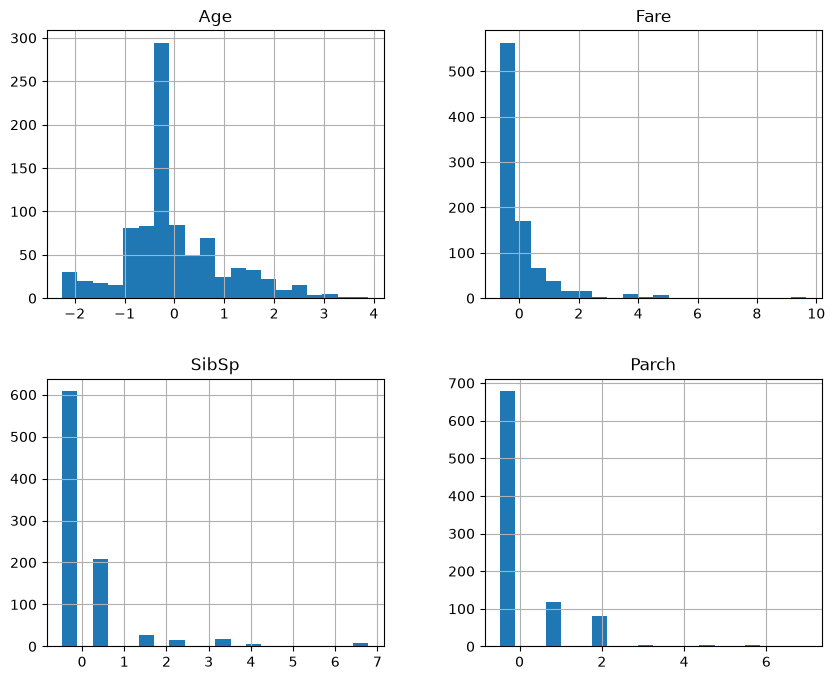

In [14]:
df[["Age","Fare","SibSp","Parch"]].hist(figsize=(10,8), bins=20)
plt.tight_layout
plt.show()

- Survival count

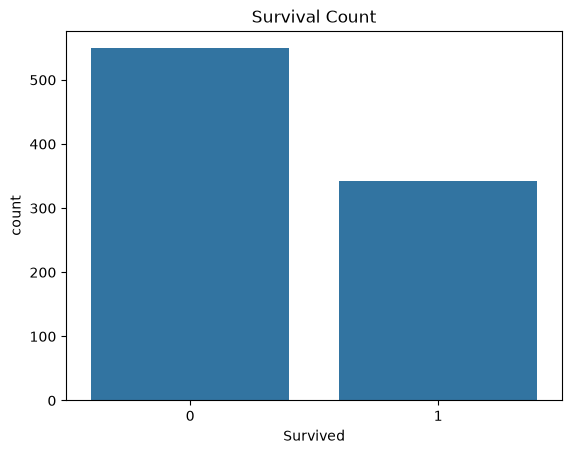

In [15]:
sns.countplot(data=df, x='Survived')
plt.title('Survival Count')
plt.show()

- Survival count by gender

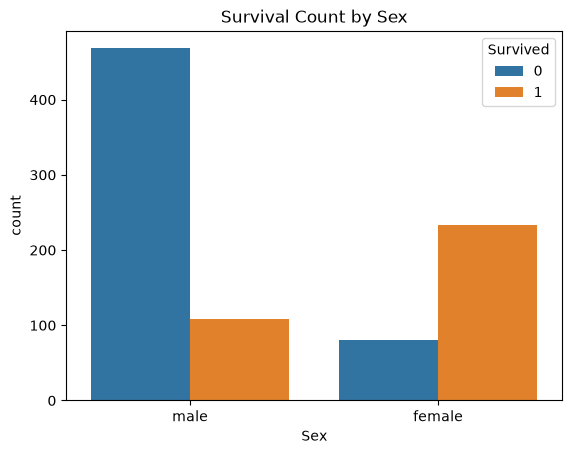

In [16]:
sns.countplot(data=df,x='Sex',hue='Survived')
plt.title('Survival Count by Sex')
plt.show()

- Fare Distribution

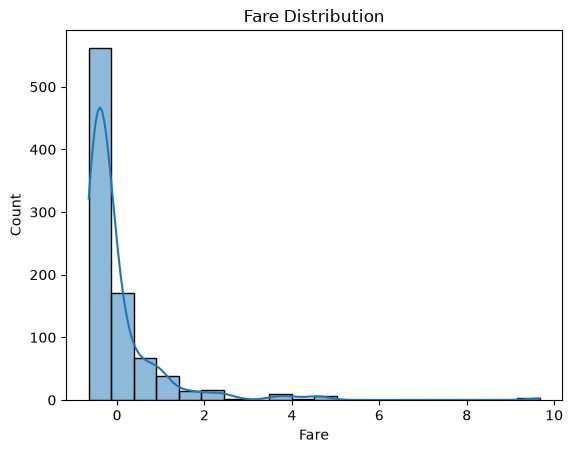

In [17]:
sns.histplot(data =df['Fare'], bins=20, kde=True)
plt.title('Fare Distribution')
plt.show()

- Survival by passenger class

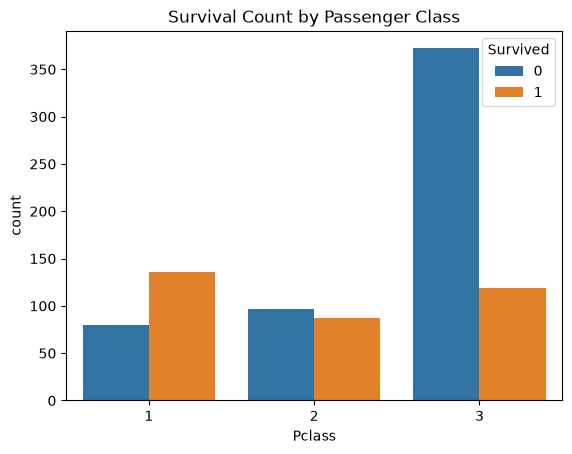

In [18]:
sns.countplot(data=df, x='Pclass', hue='Survived')
plt.title('Survival Count by Passenger Class')
plt.show()

- Before calculating correlation selecting numerical columns

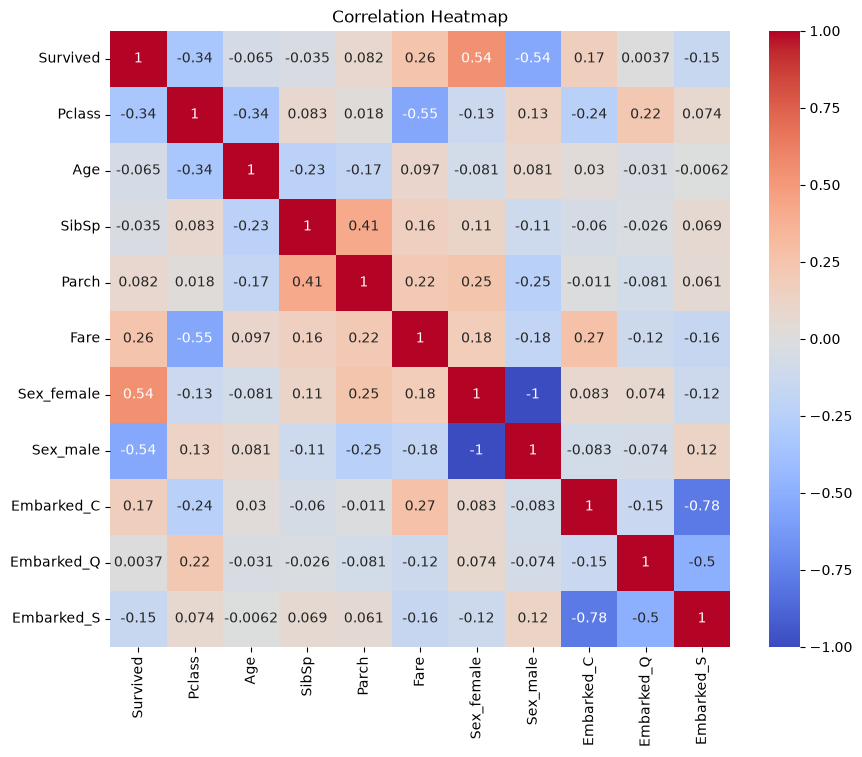

In [19]:
numerical_col = df.select_dtypes(include=np.number)
correlation = numerical_col.corr()
plt.figure(figsize=(10,8))
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

- dropping unnecessary variables

In [26]:
df = df.drop(['Sex', 'Embarked'], axis=1)

## Week 2 Task: Supervised Machine Learning Models

In [27]:
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [28]:
df=titanic.copy()

- Preparing the features and target

In [29]:
# Select relevant input features
features = ["Pclass","Sex","Age","SibSp","Parch","Fare","Embarked"]

X = df[features]
y = df["Survived"]

- Splitting the data

In [30]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 712
Testing records: 179


- Preprocessing numerical and categorical features

In [31]:
numerical_features = ["Pclass","Age","SibSp","Parch","Fare"]

categorical_features = ["Sex","Embarked"]

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")),("encoder", OneHotEncoder(handle_unknown="ignore"))])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[("num", numerical_transformer, numerical_features),("cat", categorical_transformer, categorical_features)])

- Training four classification models

In [32]:
models = {"Logistic Regression": LogisticRegression(max_iter=1000),
          "Decision Tree": DecisionTreeClassifier(max_depth=5,random_state=42),
          "Random Forest": RandomForestClassifier(n_estimators=200,random_state=42),
          "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5)}

results = []
trained_models = {}

for model_name, model in models.items():

    # Combine preprocessing and model
    pipeline = Pipeline(steps=[("preprocessor", preprocessor),("model", model)])

    # Train the model
    pipeline.fit(X_train, y_train)

    # Predict test-set outcomes
    y_pred = pipeline.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    y_prob = pipeline.predict_proba(X_test)[:, 1]

    auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": auc
    })

    trained_models[model_name] = pipeline

# Display comparison
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(by="F1-Score",ascending=False)

print(results_df.round(3))

                 Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
3  K-Nearest Neighbors     0.816      0.800   0.696     0.744    0.850
2        Random Forest     0.816      0.800   0.696     0.744    0.830
0  Logistic Regression     0.804      0.793   0.667     0.724    0.844
1        Decision Tree     0.765      0.755   0.580     0.656    0.797


- Visualizing model performance

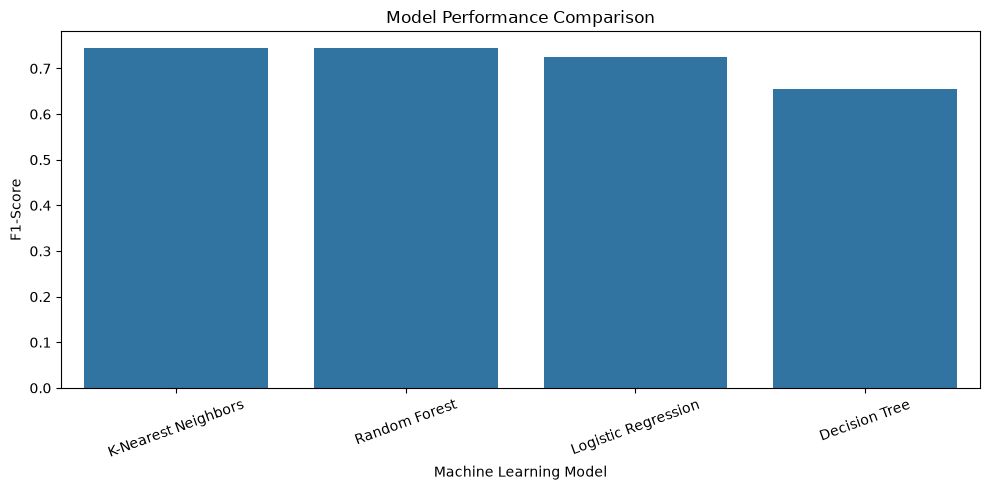

In [33]:
plt.figure(figsize=(10, 5))

sns.barplot(data=results_df,x="Model",y="F1-Score")

plt.title("Model Performance Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("F1-Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

- classification report

In [34]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

y_pred = best_model.predict(X_test)

print("Selected model:", best_model_name)

print(classification_report(y_test,y_pred,target_names=["Did Not Survive", "Survived"],zero_division=0))

Selected model: K-Nearest Neighbors
                 precision    recall  f1-score   support

Did Not Survive       0.82      0.89      0.86       110
       Survived       0.80      0.70      0.74        69

       accuracy                           0.82       179
      macro avg       0.81      0.79      0.80       179
   weighted avg       0.81      0.82      0.81       179



- Confusion Matrix

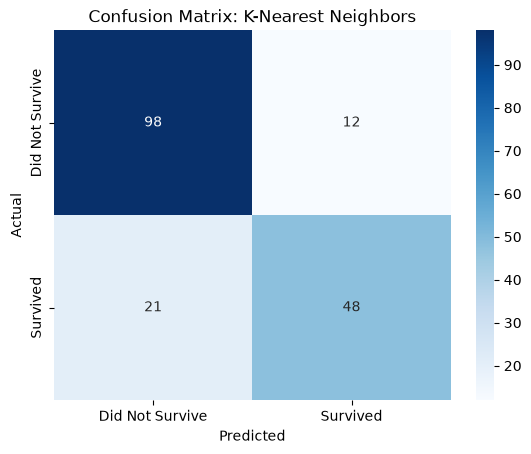

In [35]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=["Did Not Survive", "Survived"],yticklabels=["Did Not Survive", "Survived"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix: {best_model_name}")
plt.show()